# Plot astrophysical factor angular dependence
This notebook describes how to generate a radial/angular profile of the astrophysical factor previously generated with `CLUMPY`.

Authors: Gonzalo Rodriguez Fernandez gonzalo.rodriguez.fernandez@roma2.infn.it, Michele Doro michele.doro@unipd.it

Last update: 2024.03.04

### General imports

In [14]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.offsetbox import AnchoredText
import pandas as pd
import numpy as np
import glob as glob
from scipy.interpolate import interp1d, make_interp_spline, BSpline

#### Definition of path and functions

In [15]:
# Define paths for astrophysical profiles
path_j = "../clumpy/Jfactors/profile/"
path_d = "../clumpy/Dfactors/profile/"
!ls -l {path_j}
!ls -l {path_d}

total 0
drwx------@ 10 mdoro  staff  320 Apr  9 12:32 Burkert
drwx------@ 10 mdoro  staff  320 Apr  9 12:32 Einasto
total 0
drwx------@ 10 mdoro  staff  320 Apr  9 12:32 Burkert
drwx------@ 10 mdoro  staff  320 Apr  9 12:32 Einasto


In [16]:
# Extract data from files with DM annihilation profiles
def jfactor_inter1d(name, profile):
    
    if (profile=="Einasto"):
        filename=path_j+profile+'/rvir_'+name+'_MCMC.dat.Jalphaint_cls.output'
    if (profile=="Burkert"):
        filename=path_j+profile+'/rvir_'+name+'_MCMC.dat.Jalphaint_cls.output'
        
    df_j = pd.read_csv(filename,
                sep='\s+',
                header=None,
                comment='#',
                names=['alpha','jfactor','d1','d2','d3','dw1s','up1s','dw2s','up2s'])

    return np.array([interp1d(df_j.alpha.values, df_j.jfactor.values, kind="quadratic"),
                     interp1d(df_j.alpha.values, df_j.dw1s.values, kind="quadratic"), 
                     interp1d(df_j.alpha.values, df_j.up1s.values, kind="quadratic")])

In [17]:
# Extract data from files with DM decay profiles
def dfactor_inter1d(name, profile):
       
    if (profile=="Einasto"):
        filename=path_d+profile+'/rvir_'+name+'_MCMC.dat.Dalphaint_cls.output'
    if (profile=="Burkert"):
        filename=path_d+profile+'/rvir_'+name+'_MCMC.dat.Dalphaint_cls.output'
            
    df_j = pd.read_csv(filename,
                sep='\s+',
                header=None,
                comment='#',
                names=['alpha','jfactor','d1','d2','d3','dw1s','up1s','dw2s','up2s'])

    return np.array([interp1d(df_j.alpha.values, df_j.jfactor.values, kind="quadratic"),
                     interp1d(df_j.alpha.values, df_j.dw1s.values, kind="quadratic"), 
                     interp1d(df_j.alpha.values, df_j.up1s.values, kind="quadratic")])

## DM annihilation profiles
In this section we plot the profiles for Einasto and Burkert DM annihilation models

#### Target name definition 

In [18]:
df_input = pd.read_csv('AstroProfiles_dsph_parameters.csv')

# dSph names
dSphNames = df_input['dSphNames'].values 

# Other parameters
# - distance kpc
# - Rtidal_einasto: tidal radius according to Einasto profile in kpc
# - Rtidal_burkert: tidal radius according to Burkert profile in kpc
distance       = df_input['distance'].values 
Rtidal_einasto = df_input['Rtidal_einasto'].values 
Rtidal_burkert = df_input['Rtidal_burkert'].values 
alpha_opt      = df_input['alpha_opt'].values 
chi2_Einasto = df_input['chi2_Einasto'].values 
chi2_Burkert = df_input['chi2_Burkert'].values 
channels = ['b','Tau']

alpha_Einasto_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_einasto,distance)))
alpha_Burkert_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_burkert,distance)))


df_input.head(10)

,Unnamed: 0,dSphNames,distance,Rtidal_einasto,Rtidal_burkert,alpha_opt,chi2_Einasto,chi2_Burkert
0,0,CBe,42,6.30,19.00,0.20,1.467308,1.439623
1,1,DraI,75,4.83,4.30,0.23,1.391558,1.389849
2,2,RetII,32,1.70,5.80,0.15,1.954545,1.800000
3,3,Scl,84,2.95,3.71,0.29,1.348967,1.347935
4,4,SgrII,67,3.70,4.20,0.06,1.978571,1.860000
5,5,UMaII,38,2.10,2.20,0.09,2.376923,2.214286
6,6,UMi,78,14.70,15.30,0.57,1.483478,1.480477
7,7,Wil1,43,1.20,1.35,0.08,1.408108,1.381579


In [32]:
angle_fixed = np.array([0.1,0.3,0.5,1.0,2.,3.])
print(angle_fixed)
for src in dSphNames:
    print(f'{src:5s}',end=" ")
    for angle in angle_fixed:
        median = jfactor_inter1d(name=src, profile='Einasto')[0](angle)
        print(f'{median:.2e}',end=' ')
    print()


[0.1 0.3 0.5 1.  2.  3. ]
CBe   5.46e+18 2.36e+19 3.74e+19 5.98e+19 8.23e+19 8.96e+19 
DraI  1.87e+18 3.92e+18 4.77e+18 5.49e+18 5.81e+18 5.89e+18 
RetII 1.79e+18 6.24e+18 8.92e+18 1.64e+19 1.99e+19 2.06e+19 
Scl   1.52e+18 2.50e+18 2.62e+18 2.64e+18 2.66e+18 2.66e+18 
SgrII 4.11e+18 7.68e+18 8.44e+18 9.65e+18 1.03e+19 1.07e+19 
UMaII 1.33e+18 5.79e+18 8.23e+18 1.29e+19 1.82e+19 2.01e+19 
UMi   1.44e+18 8.98e+18 1.88e+19 4.16e+19 6.99e+19 8.17e+19 
Wil1  8.78e+18 1.34e+19 1.46e+19 1.69e+19 1.87e+19 1.94e+19 


#### Plot

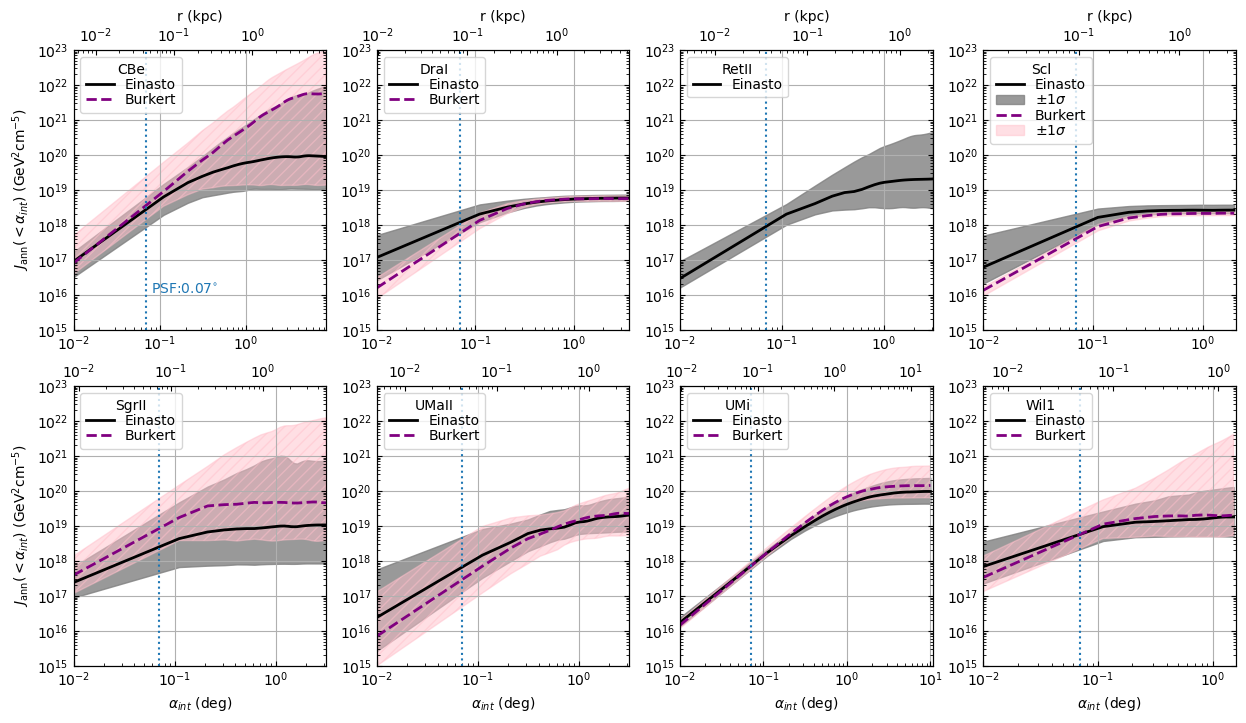

In [20]:
fig, ax_main = plt.subplots(2,4,figsize=(15,8))

x_new = np.linspace(0.01,10,100) 

counter = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
    Rt_ein = alpha_Einasto_tidal[counter-1]
    Rt_bur = alpha_Burkert_tidal[counter-1]
    alpha_optimal = alpha_opt[counter-1]
    
    x_cut = x_new[x_new<=Rt_ein]
    r_kpc = distance[counter-1] * np.tan(np.deg2rad(x_cut))
    
    counter = counter + 1

    # Plot the Einasto profiles
    #
    #
    j_inter,j_dw1s,j_up1s = jfactor_inter1d(name=name, profile='Einasto')
 
    ax.plot(x_cut,j_inter(x_cut), linewidth=2, color='black',label="Einasto")

    if name == "Scl":
        ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey',  label=r"$\pm1\sigma$", alpha=0.8)
    else:
       ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey', alpha=0.8)
        
    # Plot the Burkert profiles 
    jb_inter,jb_dw1s,jb_up1s = jfactor_inter1d(name=name, profile='Burkert')

    if (name != "RetII"):
        ax.plot(x_cut,jb_inter(x_cut), linewidth=2, linestyle='--', color='purple', label='Burkert')
        if name == "Scl":
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink',  label=r"$\pm1\sigma$", alpha=0.5)
        else:
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink', alpha=0.5, hatch='///')
        
    # Plot PSF
    ax.axvline(x = 0.07, color = 'tab:blue', linestyle='dotted')
    if name == "CBe":
        ax.text(0.08, 1.1e16, r'PSF:$0.07^{\circ}$', fontsize=10, color='tab:blue')


        
        
    # Compute a 2nd axis with distances instead of angles
    ax2 = ax.twiny()
    ax2.plot(r_kpc,j_inter(x_cut), linewidth=0, color='black',  label='Einasto')
    ax2.loglog()
    
    if counter-1 == 1 or counter-1 == 5:
        ax.set_ylabel(r"$J_{\rm ann}(<\alpha_{int})$ (GeV$^2$cm$^{-5}$)", fontsize=10)
    
    if counter-1 >= 5:
        ax.set_xlabel(r"$\alpha_{int}$ (deg)", fontsize=10)
    else:
        ax2.set_xlabel(r"r (kpc)", fontsize=10)

    '''
    font = {'family': 'serif',
            'color':  'darkred',
            'weight': 'normal',
            'size': 10,
            }
   '''

    ax.set_ylim(1e15,1e23)
    ax.set_xlim(1e-2,Rt_ein)
    ax.loglog()
    ax.grid()
    ax.tick_params(which='both', direction='in', top=False, right=True)
    ax2.tick_params(which='both', direction='in', top=True, right=True)

    ax.legend(title=name, fontsize=10, loc='upper left', labelspacing=0.1)
    
#plt.savefig('plot_profiles_jfactor_all.png', bbox_inches='tight', pad_inches=0.3)



plt.show()

## DM decay Profiles
This part generates the plots for DM Einasto/Burkert decay profile

#### Target name definition 

In [ ]:
dSphNames = ['CBe','DraI','RetII', 'Scl', 'SgrII', 'Wil1']
distance = [42, 75, 32, 84, 67, 43]
Rtidal_einasto = [6.3, 4.83, 1.7, 2.95, 3.7, 1.20]
Rtidal_burkert = [19, 4.3, 5.8, 3.71, 4.2,  1.35]
alpha_opt = [0.20, 0.23, 0.15, 0.29, 0.06, 0.08]
#chi2_Einasto = [76.3/52, 642.9/462, 21.5/11, 1501.4/1113, 27.7/14, 30.9/13, 682.4/460, 52.1/37]
#chi2_Burkert = [76.3/53, 643.5/463, 21.6/12, 1501.6/1114, 27.9/15, 31.0/14, 682.5/461, 52.5/38]
channels = ['b','Tau']

alpha_Einasto_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_einasto,distance)))
alpha_Burkert_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_burkert,distance)))

#### Plots

In [ ]:
fig, ax_main = plt.subplots(2,3,figsize=(12,8))

x_new = np.linspace(0.01,10,100) 

counter = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
    Rt_ein = alpha_Einasto_tidal[counter-1]
    Rt_bur = alpha_Burkert_tidal[counter-1]
    alpha_optimal = alpha_opt[counter-1]
    
    x_cut = x_new[x_new<=Rt_ein]
    r_kpc = distance[counter-1] * np.tan(np.deg2rad(x_cut))
    
    counter = counter + 1

    # Plot the Einasto profiles
    #
    #
    j_inter,j_dw1s,j_up1s = dfactor_inter1d(name=name, profile='Einasto')
 
    ax.plot(x_cut,j_inter(x_cut), linewidth=2, color='black',label="Einasto")

    if name == "Scl":
        ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey',  label=r"$\pm1\sigma$", alpha=0.8)
    else:
       ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey', alpha=0.8)
        
    # Plot the Burkert profiles 
    jb_inter,jb_dw1s,jb_up1s = dfactor_inter1d(name=name, profile='Burkert')

    if (name != "RetII"):
        ax.plot(x_cut,jb_inter(x_cut), linewidth=2, linestyle='--', color='purple', label='Burkert')
        if name == "Scl":
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink',  label=r"$\pm1\sigma$", alpha=0.5)
        else:
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink', alpha=0.5, hatch='///')
        
    # Plot PSF
    ax.axvline(x = 0.07, color = 'tab:blue', linestyle='dotted')
    if name == "CBe":
        ax.text(0.08, 1.1e16, r'PSF:$0.07^{\circ}$', fontsize=10, color='tab:blue')


        
        
    # Compute a 2nd axis with distances instead of angles
    ax2 = ax.twiny()
    ax2.plot(r_kpc,j_inter(x_cut), linewidth=0, color='black',  label='Einasto')
    ax2.loglog()
    
    if counter-1 == 1 or counter-1 == 4:
        ax.set_ylabel(r"$J_{\rm ann}(<\alpha_{int})$ (GeV$^2$cm$^{-5}$)", fontsize=10)
    
    if counter-1 >= 4:
        ax.set_xlabel(r"$\alpha_{int}$ (deg)", fontsize=10)
    else:
        ax2.set_xlabel(r"r (kpc)", fontsize=10)

    '''
    font = {'family': 'serif',
            'color':  'darkred',
            'weight': 'normal',
            'size': 10,
            }
   '''

    ax.set_ylim(1e15,1e23)
    ax.set_xlim(1e-2,Rt_ein)
    ax.loglog()
    ax.grid()
    ax.tick_params(which='both', direction='in', top=False, right=True)
    ax2.tick_params(which='both', direction='in', top=True, right=True)

    ax.legend(title=name, fontsize=10, loc='upper left', labelspacing=0.1)
    
plt.savefig('plot_profiles_dfactor_all.png', bbox_inches='tight', pad_inches=0.3)



plt.show()